Use the `bigmap` conda environment.

In [ ]:
import datashader as ds
import datashader.transfer_functions as tf
import pandas as pd
import colorcet as cc
import geopandas as gpd

### Visualize the locations of the AEF training samples

In [5]:
df = pd.read_csv("training_coordinates.csv")
canvas = ds.Canvas(plot_width=2400, plot_height=1600)
agg = canvas.points(df, 'longitude', 'latitude')

# 'eq_hist' stretches the colors so you can see low-density and high-density areas clearly
img = tf.shade(agg, cmap=cc.fire, how='eq_hist')
img.to_pil().save("distribution_map.png")

<Axes: >

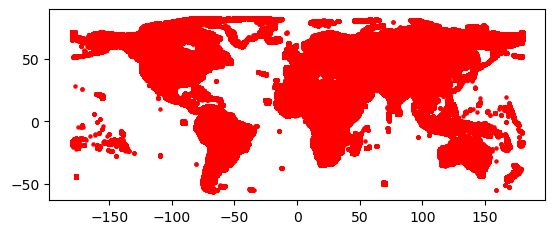

In [4]:
# Make an interactive map using GeoPandas and Matplotlib
df = pd.read_csv("training_coordinates.csv")
gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude))
gdf.plot(marker='o', color='red', markersize=5)

### Load the AEF training samples for a given Sentinel-2 tile

In [ ]:
path_shp = "/scratch3/gsialelli/BiomassDatasetCreation/Data/download_Sentinel/sentinel_2_index_shapefile.shp"
grid_s2_df = gpd.read_file(path_shp, engine = 'pyogrio')
df = pd.read_csv("training_coordinates.csv")
gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326")
s2_tile = '32TNN'
s2_tile_geom = grid_s2_df[grid_s2_df['Name'] == s2_tile].geometry.values[0]
gdf_within_tile = gdf[gdf.within(s2_tile_geom)]

gdf_within_tile